# ConstructPortfolio
- DuelNet_2026で学習したNNモデルのポートフォリオを作成する

## Dependancy
- このパッケージを実行する前にPyPortfolioOptをインストールする
- バックテスト部分は既存のコードをインポートする

In [1]:
import glob
from collections import namedtuple
from pypfopt.efficient_frontier import EfficientFrontier
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
%matplotlib inline
from scipy import stats
import gc
import connectorx as cx

## TradingSystem2027からのインポート

In [2]:
# 共通コアモジュールのインポート
import TradingSystem2027_comandline as ts

## Logger

In [3]:
import logging
import logging.config
import configparser
logconfigfile = configparser.ConfigParser()
logconfigfile.read(ts.LOGGING_INIFILE_PATH,ts.ENC)
logging.config.fileConfig(logconfigfile)
logger_portfolio = logging.getLogger('DRLPortfolio')

## Class PortfolioContracter

In [4]:
class PortfolioConstructer:

  def __init__(self,target_ex):
    self.target_excepted_value = target_ex
    pass

  def ConstructPortfolio(self,df_models):
    # df_modelの内容をプロットする？

    # モデルの平均、分散・共分散行列を計算する
    self.np_models = df_models.to_numpy()
    self.np_cov = np.cov(self.np_models,rowvar=False,bias=True)
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:CovMatrix=======\n%s' %(self.np_cov))
    self.np_mean = np.mean(self.np_models,axis=0)
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:Means=======\n%s'%(self.np_mean))
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:Min mean=%.4f'%(self.np_mean.min()))
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:Max mean=%.4f'%(self.np_mean.max()))

    self.S = pd.DataFrame(self.np_cov,columns=df_models.columns)
    self.mu = pd.Series(self.np_mean,index=df_models.columns)
    self.ef = EfficientFrontier(self.mu, self.S)
    self.w_min_dict = self.ef.min_volatility() # 戻り値は辞書型
    self.w_min_np = pd.Series(self.w_min_dict).values
    self.pf_mu_min = np.dot(self.mu,self.w_min_np.T)
    self.v_min = np.sqrt(np.dot(np.dot(self.w_min_np,self.np_cov),self.w_min_np.T)) # 標準偏差の計算
    logger_portfolio.info('EfficientFrontier.ConstructPortfolio:min_volatility pf_mu_min=%.4f, v_min=%.4f' %(self.pf_mu_min,self.v_min))

    # ポートフォリオを構成する各nnの期待値がtarget_expected_valeより小さい場合は、ポートフォリオ内の最大の期待値(np_mean.max())とする
    if self.np_mean.max() < self.target_excepted_value:
      self.ef = EfficientFrontier(self.mu, self.S)
      # self.w_dict = self.ef.efficient_return(target_return=self.np_mean.max())
      self.w_dict = self.ef.efficient_return(target_return=self.np_mean.max()*0.99)
      self.w_np = pd.Series(self.w_dict).values
      self.pf_mu = np.dot(self.mu,self.w_np.T) # ポートフォリオの期待値
      self.v = np.sqrt(np.dot(np.dot(self.w_np,self.np_cov),self.w_np.T)) # 分散の計算
    # リスク最小の期待値がtarget_expected_valeより小さい場合は期待値が1.0のポートフォリオを採用する
    elif self.pf_mu_min < self.target_excepted_value:
      self.ef = EfficientFrontier(self.mu, self.S)
      self.w_dict = self.ef.efficient_return(target_return=self.target_excepted_value)
      self.w_np = pd.Series(self.w_dict).values
      self.pf_mu = np.dot(self.mu,self.w_np.T) # ポートフォリオの期待値
      self.v = np.sqrt(np.dot(np.dot(self.w_np,self.np_cov),self.w_np.T)) # 分散の計算
    # リスク最小の期待値がtarget_expected_vale以上の場合はリスク最小におけるポートフォリオを採用する
    else:
      self.w_dict = self.w_min_dict
      self.w_np = self.w_min_np
      self.pf_mu = self.pf_mu_min # ポートフォリオの期待値
      self.v = self.v_min

    self.w_dict['mu'] = self.pf_mu
    self.w_dict['sigma'] = self.v
    logger_portfolio.info('EfficientFrontier.ConstructPortfolio:pf_mu=%.4f, v=%.4f' %(self.pf_mu,self.v))
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:Portfolio=====\n%s' %(self.w_dict))

    return self.w_dict

  def SavePortfolioFile(self,m_dict):
    # NN モデルのポートフォリオをModelPortfolio.iniファイルに保存する
    self.p_ini = configparser.ConfigParser()
    self.p_ini['LOCAL'] = m_dict

    with open (ts.TRADE_MODEL_PATH+ts.MODEL_PORTFOLIO_FILE_NAME,'w') as fp:
      self.p_ini.write(fp)
    return

  def DrawEfficientFrontier(self, df_models):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from pypfopt import EfficientFrontier

    # モデルの平均、分散・共分散行列を計算する
    self.np_models = df_models.to_numpy()
    self.np_cov = np.cov(self.np_models, rowvar=False, bias=True)
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:CovMatrix=======\n%s' % (self.np_cov))
    self.np_mean = np.mean(self.np_models, axis=0)
    logger_portfolio.debug('EfficientFrontier.ConstructPortfolio:Means=======\n%s' % (self.np_mean))
    
    self.S = pd.DataFrame(self.np_cov, columns=df_models.columns)
    self.mu = pd.Series(self.np_mean, index=df_models.columns)

    # 期待値の最小から最大までを50分割する
    min_ret = self.np_mean.min()
    max_ret = self.np_mean.max()
    self.trets = np.linspace(min_ret, max_ret, 50)
    
    self.tvols = []
    valid_trets = []
    
    for tr in self.trets:
      try:
        mu_copy = pd.Series(self.mu.values, index=self.mu.index)
        S_copy = pd.DataFrame(self.S.values, columns=self.S.columns, index=self.S.index)
        
        ef_loop = EfficientFrontier(mu_copy, S_copy)
        w = ef_loop.efficient_return(target_return=tr)
        w = pd.Series(w).values
        v = np.sqrt(np.dot(np.dot(w, self.np_cov), w.T))
        self.tvols.append(v)
        valid_trets.append(tr)
      except Exception as e:
        logger_portfolio.warning(f"Could not optimize for target return {tr:.4f}: {e}")

    # 描画処理
    plt.style.use('ggplot')
    fig = plt.figure(figsize=(16, 8))
    ax = fig.add_subplot(1, 1, 1)
    
    if self.tvols:
      # 効率的フロンティアの曲線をプロット
      ax.plot(self.tvols, valid_trets, marker='x', linestyle='-', color='blue', label='Efficient Frontier')
    else:
      logger_portfolio.error("No valid optimization results to plot.")

    # 各資産（モデル）単体のリスク・リターンをプロット
    asset_vols = np.sqrt(np.diag(self.np_cov))
    ax.scatter(asset_vols, self.np_mean, color='red', s=100, zorder=4, label='Individual Models')
    
    # 各モデルのテキストラベルを表示
    for i, name in enumerate(df_models.columns):
        ax.text(asset_vols[i] * 1.02, self.np_mean[i], name, fontsize=12, fontweight='bold', va='center')

    # ----------------------------------------------------
    # 【追加機能】決定された最適ポートフォリオの位置に星印（★）をプロット
    # ----------------------------------------------------
    # ConstructPortfolio() が先に実行され、インスタンス変数に値があるかチェック
    if hasattr(self, 'v') and hasattr(self, 'pf_mu'):
        # 大きなゴールドの星マーク（marker='*'）をプロット
        ax.scatter(self.v, self.pf_mu, color='gold', edgecolor='black', marker='*', s=400, zorder=5, label='Selected Portfolio')
        # 星印の少し上にテキストラベルを表示
        ax.text(self.v, self.pf_mu * 1.05, 'SELECTED', fontsize=14, color='darkgoldenrod', fontweight='bold', ha='center', va='bottom')
    else:
        logger_portfolio.warning("ConstructPortfolio() has not been run yet. Star marker skipped.")
    # ----------------------------------------------------

    # 軸の範囲を設定
    max_x = max(max(self.tvols) if self.tvols else 0, max(asset_vols))
    ax.set_xlim([0.0, max_x * 1.2])
    
    y_min = min(0.0, min_ret * 1.2)
    ax.set_ylim([y_min, max_ret * 1.2])
    
    ax.set_xlabel('Volatility (Risk)')
    ax.set_ylabel('Expected return')
    ax.set_title('Efficient Frontier with Selected Portfolio')
    ax.legend(loc='upper left')
    ax.grid(True)
    plt.show()

## MakeTrainData and Construct a Portfolio
### 処理の流れ
- TrainディレクトリにあるNN Modelパラメータ(.pthファイル)を取得する
- 2018-2022のバックテストを行う。結果をCSVファイルに出力する
- バックテストの結果をもとに、効率的フロンティアを作成しポートフォリオを構成する

### 今後の追加機能
- 特定の時間足だけを対象にポートフォリオを作成する
- バックテスト期間を設定できるようにする
  - 直前週から過去１年間など

In [5]:
if __name__ == '__main__':
  ACCOUNT_TRADE_MODE = ts.ACCOUNT_TRADE_MODE_REAL #@param ["ACCOUNT_TRADE_MODE_DEMO", "ACCOUNT_TRADE_MODE_CONTEST", "ACCOUNT_TRADE_MODE_REAL", "ACCOUNT_TRADE_MODE_DEMOXM"] {type:"raw"}
  TEST_SYMBOL = "*" # @param ["*", "EURUSD", "USDJPY", "GBPUSD", "EURJPY", "EURGBP", "GBPJPY", "GBPAUD", "GBPNZD"]
  TEST_PERIOD = "*" #@param ["*","D1", "H12", "H8", "H6","H4", "H1", "M30", "M5", "M1"]
  TEST_GRADE = "[PMC]" #@param ["*","G","S","B","[GS]","[SB]","[BG]"]
  TEST_MAGIC = "*" #@param {type:"string"}
  
  INPUT_ALL_SYMBOLS_FLG = True

  EPISODE_NUM = 1 #@param {type:"integer"}
  # テスト期間は1episodeの長さ。1日(D)、1週間(W)、1年(Y)を選択する
  TEST_DURATION = 'W' #@param ['D', 'W', 'Y']
  BACKTEST_START_YEAR = 2022 #@param {type:"slider", min:2018, max:2030, step:1}
  BACKTEST_END_YEAR = 2024 #@param {type:"slider", min:2018, max:2030, step:1}
  BACKTEST_DURATION = 'W' #@param ['D', 'W', 'Y']
  LOAD_FLAG = True
  # LONG,SHORT,TICKVO+_PERIODをランダムに選択するか
  PERIOD_RANDOM_SELECT = False
  # ファイルパスを設定する
  ts.TrainEnvHelper.setTradeModePath(ACCOUNT_TRADE_MODE)
  nn_model_params=glob.glob('%sModel_%s_%s_%s_%s.pth'%(ts.TRAIN_MODEL_PATH,TEST_SYMBOL,TEST_PERIOD,TEST_GRADE,TEST_MAGIC))

  TrainParameters = namedtuple('TrainParameters', ['account','agent','brain'])
  TrainParametersList=[TrainParameters(None,None,None)]*len(nn_model_params)
  # ModelNameとMAGICを格納するNamedTaple
  ModelName = namedtuple('ModelName',['model_name','magic'])
  ModelNameList = [ModelName(None,None)]*len(nn_model_params)
  
  # backtestの結果を格納するDataFrame
  df_models = pd.DataFrame()
  
  # Protfolioファイルの読み込み
  portfolio = configparser.ConfigParser()

  ts.TrainEnvHelper.connectDB()
  logger_portfolio.debug("CONN_URL Created.")

  # NN Modelのパラメータを読み込む
  for i, mprm in enumerate(nn_model_params):
    periods_dict = {}
    prices_dict = {}
    train_data_dict = {}
  
    s = mprm.split('_') # Model_GBPJPY_H6_B_20230908223249.pth
    TRADE_SYMBOL = s[2]
    TRADE_PERIOD = s[3]
    TRADE_GRADE = s[4]
    MAGIC = s[5].split('.')[0]
    TrainParametersList[i] = TrainParameters(account=ts.TRAIN_MODEL_PATH+'Account_'+TRADE_SYMBOL+'_'+TRADE_PERIOD+'_'+TRADE_GRADE+'_'+MAGIC+'.ini',
                                  agent=ts.TRAIN_MODEL_PATH+'Agent_'+TRADE_SYMBOL+'_'+TRADE_PERIOD+'_'+TRADE_GRADE+'_'+MAGIC+'.ini',
                                  brain=mprm)
    ModelNameList[i] = ModelName(model_name=TRADE_SYMBOL+'_'+TRADE_PERIOD+'_'+TRADE_GRADE+'_'+MAGIC, magic=MAGIC)
  
    logger_portfolio.debug('ConstructPortfolio:TrainParameters:%s' %(str(TrainParametersList[i])))
    logger_portfolio.debug('ConstructPortfolio:ModelName:%s' %(str(ModelNameList[i])))
    logger_portfolio.info('ConstructPortfolio:%s_%s_%s_%s Parameters Loaded.' %(TRADE_SYMBOL,TRADE_PERIOD,TRADE_GRADE,MAGIC))

    logger_portfolio.debug('ConstructPortfolio: INIFile loading. \n %s' %(TrainParametersList[i].account))

    # 全MTF [W1, D1, H4, H1] の価格CSVを展開
    periods_dict = {tf: {} for tf in ts.MTF_TIMEFRAMES}
    for tf in ts.MTF_TIMEFRAMES:
        p_obj = ts.PriceData(TRADE_SYMBOL, tf)
        p_obj.ConvertPriceDataFileToDataFrame()
        periods_dict[tf][TRADE_SYMBOL] = p_obj
    
    s_format = '%Y%m%d%H%M%S'
    test_date_time = datetime.datetime.strptime(MAGIC, s_format)

    # Account.iniに書き込まれているLONG_PERIOD,SHORT_PERIOD,TICKVOL_PRIOを読み込む
    acc_inifile = configparser.ConfigParser()
    acc_inifile.read(TrainParametersList[i].account)
    periods = [
        int(acc_inifile.get('COMMOM', 'LONG_PERIOD')),
        int(acc_inifile.get('COMMOM', 'SHORT_PERIOD')),
        int(acc_inifile.get('COMMOM', 'TICKVOL_PERIOD'))
    ]
    mtf_data = ts.MTFTrainData(TRADE_SYMBOL, periods_dict, periods)
    trnr = ts.Trainer(EPISODE_NUM, TRADE_SYMBOL, test_date_time, TEST_DURATION,1,1, mtf_data, periods_dict, LOAD_FLAG,
                      filepth=TrainParametersList[i], prds=periods,)
  
    df_backtest_result = trnr.ExecBacktest(BACKTEST_START_YEAR,BACKTEST_END_YEAR,BACKTEST_DURATION)
    df_backtest_result.to_csv(ts.TRADE_RESULT_PATH+'BacktestResultP_'+TRADE_SYMBOL+'_'+TRADE_PERIOD+'_'+TRADE_GRADE+'_'+MAGIC+'.csv')
    df_models['sum'] = df_backtest_result['sum']
    df_models = df_models.rename(columns={'sum':ModelNameList[i].model_name})

    # BackTest Resultの出力
    result = df_backtest_result['sum'].sum()
    trade_avg = df_backtest_result['sum'].mean()
    std = df_backtest_result['sum'].std()
    cdp_0 = stats.norm(loc=trade_avg, scale=std).cdf(0)
    eval_value = trade_avg * cdp_0 if trade_avg < 0 else trade_avg * (1 - cdp_0)
    
    logger_portfolio.info(f"[{TRADE_SYMBOL}_{TRADE_PERIOD}_{TRADE_GRADE}_{MAGIC} Result] \n"
      f"Total: {result:+7.1f}p | Mean: {trade_avg:+5.2f}p | Std: {std:5.2f} | Shortfall(CDP0): {cdp_0*100:4.1f}% | Eval: {eval_value:.4f}")

    # メモリを開放する
    del prices_dict
    del periods_dict
    del train_data_dict
    gc.collect()

  logger_portfolio.debug('ConstructPortfolio:df_models %s' %(df_models))
  df_models.to_csv(ts.TRADE_RESULT_PATH+ts.BACKTEST_ALL_FILE_NAME)
  logger_portfolio.info('ConstructPortfolio:All Synbol and Period Backtest Finished.')

2026-10-24 16:54:08,360 DRLPortfolio DEBUG    CONN_URL Created.
2026-10-24 16:54:08,363 DRLPortfolio DEBUG    ConstructPortfolio:TrainParameters:TrainParameters(account='D:\\ColabNotebooks\\07_TardeSystem2027\\Real\\Model\\Train\\Account_EURJPY_System2027_M_20261019141453.ini', agent='D:\\ColabNotebooks\\07_TardeSystem2027\\Real\\Model\\Train\\Agent_EURJPY_System2027_M_20261019141453.ini', brain='D:\\ColabNotebooks\\07_TardeSystem2027\\Real\\Model\\Train\\Model_EURJPY_System2027_M_20261019141453.pth')
2026-10-24 16:54:08,364 DRLPortfolio DEBUG    ConstructPortfolio:ModelName:ModelName(model_name='EURJPY_System2027_M_20261019141453', magic='20261019141453')
2026-10-24 16:54:08,365 DRLPortfolio INFO     ConstructPortfolio:EURJPY_System2027_M_20261019141453 Parameters Loaded.
2026-10-24 16:54:08,366 DRLPortfolio DEBUG    ConstructPortfolio: INIFile loading. 
 D:\ColabNotebooks\07_TardeSystem2027\Real\Model\Train\Account_EURJPY_System2027_M_20261019141453.ini
2026-10-24 16:54:42,277 DRLTra

In [18]:
ACCOUNT_TRADE_MODE = ts.ACCOUNT_TRADE_MODE_REAL #@param ["ACCOUNT_TRADE_MODE_DEMO", "ACCOUNT_TRADE_MODE_CONTEST", "ACCOUNT_TRADE_MODE_REAL","ACCOUNT_TRADE_MODE_DEMOXM"] {type:"raw"}
# ファイルパスを設定する
ts.TrainEnvHelper.setTradeModePath(ACCOUNT_TRADE_MODE)
# portfolio系から得たい1週間当たりのpips(1,000pips =1.0)
# Gold model:1.0 Silver model:0.5 Bronz model:0.25
TARGET_EXPECTED_VALUE = 9.0 # @param {type:"raw"}
# 効率的フロンティアの計算とポートフォリオの構築
pt_const = PortfolioConstructer(TARGET_EXPECTED_VALUE)
# CSVファイルからDataFrameを作成
df_models = pd.read_csv(ts.TRADE_RESULT_PATH+ts.BACKTEST_ALL_FILE_NAME, index_col=0)
model_portfolio = pt_const.ConstructPortfolio(df_models)
pt_const.SavePortfolioFile(model_portfolio)

2026-10-24 20:24:17,384 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:CovMatrix=======
[[ 29.43355645  -0.58313632   2.11458734  -6.32769227   2.35210022]
 [ -0.58313632 153.54611027  -4.94757672   5.00588877  -3.33957911]
 [  2.11458734  -4.94757672  79.72613124   5.01651973  -3.19198172]
 [ -6.32769227   5.00588877   5.01651973 200.02658057  12.79017937]
 [  2.35210022  -3.33957911  -3.19198172  12.79017937 133.51025473]]
2026-10-24 20:24:17,385 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:Means=======
[ 6.13824667  9.83942    10.90040667 10.85191333  5.77296   ]
2026-10-24 20:24:17,385 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:Min mean=5.7730
2026-10-24 20:24:17,386 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:Max mean=10.9004
2026-10-24 20:24:17,401 DRLPortfolio INFO     EfficientFrontier.ConstructPortfolio:min_volatility pf_mu_min=7.7573, v_min=3.9263
2026-10-24 20:24:17,431 DRLPortfolio INFO     EfficientFrontier.Construct

2026-10-24 20:24:20,114 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:CovMatrix=======
[[ 29.43355645  -0.58313632   2.11458734  -6.32769227   2.35210022]
 [ -0.58313632 153.54611027  -4.94757672   5.00588877  -3.33957911]
 [  2.11458734  -4.94757672  79.72613124   5.01651973  -3.19198172]
 [ -6.32769227   5.00588877   5.01651973 200.02658057  12.79017937]
 [  2.35210022  -3.33957911  -3.19198172  12.79017937 133.51025473]]
2026-10-24 20:24:20,116 DRLPortfolio DEBUG    EfficientFrontier.ConstructPortfolio:Means=======
[ 6.13824667  9.83942    10.90040667 10.85191333  5.77296   ]
C:\Users\shana\AppData\Roaming\Python\Python313\site-packages\cvxpy\problems\problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
2026-10-24 20:24:21,211 DRLPortfolio WARNING  Could not optimize for target return 10.9004: ('Please check your objectives/constraints or use a diffe

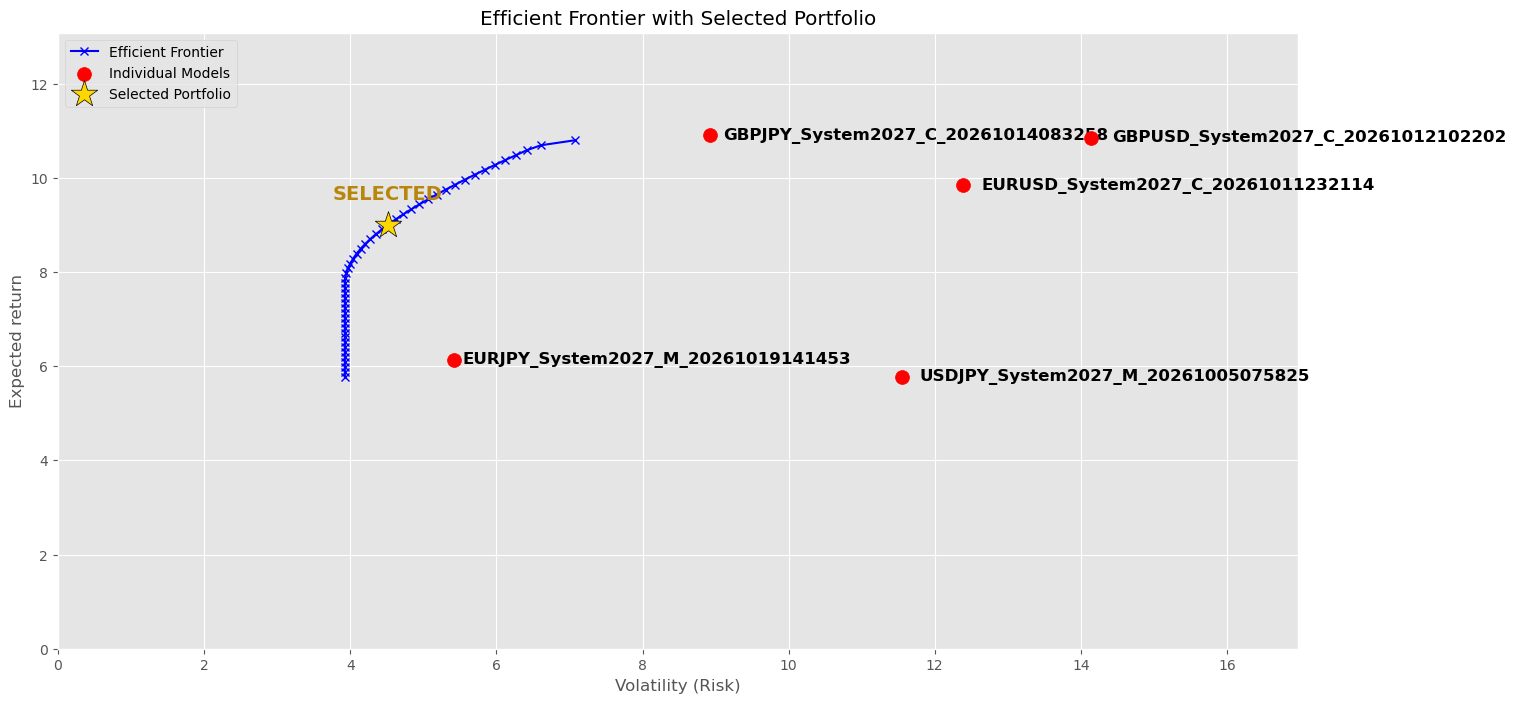

In [19]:
# 効率的フロンティアを描画する
pt_const.DrawEfficientFrontier(df_models)

In [17]:
pt_const.ef.efficient_return(target_return=9.0)

OrderedDict([('EURJPY_System2027_M_20261019141453', 0.3069839613229878),
             ('EURUSD_System2027_C_20261011232114', 0.16363799693675),
             ('GBPJPY_System2027_C_20261014083258', 0.3464372734812992),
             ('GBPUSD_System2027_C_20261012102202', 0.1325362693643074),
             ('USDJPY_System2027_M_20261005075825', 0.0504044882904717)])

In [ ]:
# pt_constが保持している mu と S を使って、その場限りの新しいefを作成する
ef_new = EfficientFrontier(pt_const.mu, pt_const.S)
# 計算を実行
weights = ef_new.efficient_return(target_return=1.0)
weights